# Case Study 1 — "When Will My Order Arrive?" Delivery-Time Prediction, the Promise Trade-off, and an ETA That Doesn't Jump

**Priority:** ★★★ Must-visit · **Reference:** Case Study 1 — *Swiggy's multi-stage ETA and delivery-time promise models* (`indian_ecommerce_data_science_case_studies.md`)
**Audience:** Head of Delivery / Customer Promise, Operations, Product (cart and tracking), Finance
**Data:** ⚠️ **SYNTHETIC** (D-1-01). Swiggy order logs are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs01_delivery_eta_prediction.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on the documented structure of Swiggy's delivery-time system: a cart-time promise, a live ETA that is refreshed by stage, and a model that predicts legs of the journey. The company's real models and data are not reproduced. Written after the analysis.)*

- **The question:** what delivery time should we show at the cart, how accurate and how honest is it, and how do we keep the live ETA from jumping around?
- **Where the uncertainty is:** the **last mile** carries **54%** of the variance of order-to-delivery time, **wait at the restaurant 22%**, first mile 13% and assignment 11%. The legs are **negatively correlated** (wait vs first mile −0.47, wait vs assignment −0.43), because a rider who arrives early simply waits longer.
- **Accuracy:** the legacy promise (band mean + 4 min) has a mean error of **9.5 min** and is on average 5 min too long. Gradient boosting on the cart features brings this to **4.6 min** (paired Δ −4.9 min, 95% CI −4.96 to −4.82), with **65%** of orders within ±5 min versus 28% for the legacy promise.
  - **Summing four independent leg models is worse (4.99 min)** because it ignores the negative correlation between legs. A joint multi-output network recovers most of it (4.67 min), but no model beats plain gradient boosting on the overall error here.
- **A promise is a quantile, not a mean:** quantile models are **well calibrated** at every level tested (coverage 50.3%, 60.4%, 70.3%, 79.9% and 89.8% for targets 50% to 90%; binomial p > 0.14 each).
- **What a promised minute costs:** in the randomised ±3 min arm, **each extra promised minute cuts the odds of placing the order by 4.0%** (OR 0.960, 95% CI 0.954 to 0.967). Placement is **69.3%** at −3 min, 66.8% at 0 and 63.9% at +3 min. The observational slope (0.957) is close, because in this simulation the confounding is mild.
- **The trade-off:** the most aggressive promise (50th percentile) earns **+₹2.20 per session** over legacy, but **20% of orders arrive more than 5 minutes after the promise** (legacy: 14.5%). **The 70th percentile earns +₹1.81 and cuts such late orders to 10.6%.** The ranking depends on the assumed lateness cost, which must be replaced by measured values.
- **Live ETA:** after pickup the error falls to **1.4 min** (from 4.6 at the cart). Chaining the stage models trims the size of ETA jumps by about 10% for early refreshes (1.21 vs 1.35 min) and almost nothing at the pickup refresh, where the jump (≈ 3.6 min) is genuine new information.
- **Fairness of the promise:** coverage is near 80% in almost every segment. Fast-prep kitchens are over-covered (81.5%, q = 0.0008), so their promise is too long. The rain segment **could not be tested**: the test week was dry.
- **Money:** about **₹60 crore a year** in the base case at the 50th percentile (₹41 crore pessimistic), and **≈ ₹50 crore** at the safer 70th percentile (derived by scaling).
- **I recommend:** ship gradient boosting for the cart promise at the **70th percentile**, run a **switchback test** (about 460 city-hour blocks per arm for +1 pp conversion), and retire the +4 min padding.

## 1. The Problem in Simple English

When you open the cart on a food-delivery app, it says "**Delivers in 32 minutes**". That number is a **promise**. Set it too short and many orders arrive late: customers contact support, cancel and stop trusting the app. Set it too long and customers see a slower app than the competitor and **don't place the order at all**. Swiggy describes this as a "Goldilocks zone".

After the order is placed, the tracking screen shows a live **ETA** that should get more accurate as the order progresses: once a rider is assigned, once the rider reaches the restaurant, once the food is picked up. A good ETA also **doesn't jump around**: customers lose trust when "12 min" becomes "20 min" then "11 min".

Questions leaders ask:
1. How accurate can a delivery-time model be, and does it beat a simple "restaurant average + buffer"?
2. Where does the time actually go (preparation, rider assignment, travel), and which part is hardest to predict?
3. **What promise should we show?** The best statistical estimate (the median) is not the best business choice.
4. How do we keep the live ETA smooth as it updates?

## 2. Reference from the Case File

### (a) What Swiggy did — *documented*

| Item | Documented fact (from the reference file) |
|---|---|
| Problem | A cart promise (pSLA) that can be "a make or break factor for placing an order" and a "double edged sword": delays upset customers, a conservative promise "reduces the propensity of the customer to place an order" (the "Goldilocks zone"); a tracking ETA that drives customer-care contacts and cancellations |
| Structure | Delivery time = max(assignment delay + first mile, prep time) + last mile; five targets O2A, FM, WT, LM, O2R with O2A + FM + WT + LM = O2R |
| Approach | Cart: one **multi-input multi-output (MIMO)** deep network with entity embeddings (restaurant, customer geohash, city). Tracking ETA: **four stage models** (ordered, assigned, arrived, picked up), refreshed at intervals, built on the cart promise; GBT with absolute loss first, then neural networks |
| Metrics | MAE; **BDC** (bi-directional compliance: share within ±X of the prediction); **ED** (egregious delay: share beyond +Y); "Percentage of Orders with Inaccurate Bumps" (sudden ETA jumps). **X, Y and absolute errors were not disclosed** |
| Impact (Swiggy's own claims) | GBT vs legacy: accuracy "~62%" better, inaccurate bumps "~27%" fewer; neural network vs GBT: "~15%" and "~12%"; MIMO cut O2A MAE "nearly 30%", embeddings cut O2R MAE "5%"; fewer care contacts and cancellations (ND) |

**Sources:** Swiggy Bytes, "Predicting Food Delivery Time at Cart" (11 Aug 2023); "Where is my order? Part I" (22 May 2023); "How ML Powers — When is my order coming? Part II" (26 May 2023); "The Swiggy Delivery Challenge Part One" (27 Sep 2018). The research agent read these through archive snapshots (the live site was unreachable).

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 220,000 cart sessions over 28 days, 3 cities, 600 restaurants; 147,000 placed orders with the five legs (O2A, FM, WT, LM, O2R). Hidden drivers: restaurant prep speed, kitchen stress, rider supply vs orders (rain and dinner peak), traffic, distance. Legacy promise = restaurant × time-band average + 4 minutes. |
| Added by us | A **randomised promise perturbation** (±3 min on the shown promise for 20% of sessions): it identifies how conversion responds to the promise. Swiggy documents the trade-off but no such experiment. |
| Statistics added | Time-based split; paired bootstrap and Wilcoxon for model comparison; BDC/ED/MAE; **quantile calibration with binomial tests**; **conversion elasticity from the randomised arm**; **expected-value choice of the promise quantile**; per-stage ETA accuracy; **bump metric** with and without chaining; calibration by segment (BH); A/B sample size |

### (c) How the industry uses this

Every delivery platform (Swiggy, Zomato, Blinkit, Zepto, Amazon, Flipkart) predicts delivery time. The standard stack is gradient boosting or neural nets on historical leg times, live supply and distance, with **quantile or asymmetric losses** and the promise set above the median. **"Promise the 80th percentile, track the median"** is a common rule. Interviewers ask about leakage, time-based validation, quantile regression and why MAE is not the right objective for a customer promise.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | What delivery time should we promise at the cart, and how should the live ETA update, to maximise orders net of late-delivery cost? |
| Analytical | (1) Which model predicts total delivery time (O2R) best out of time? (2) Which quantile should be promised when conversion falls with the promise and lateness is costly? (3) Does chaining stage models cut ETA bumps without hurting accuracy? |

**Hypotheses**
- **H1:** H0: MAE of the learned model equals the legacy promise's (paired bootstrap; Wilcoxon on absolute errors).
- **H2:** H0: a joint (multi-output) model's MAE equals independent leg models' (paired).
- **H3 (calibration):** H0: the promise at quantile τ is met with probability τ (binomial test; by segment, BH).
- **H4 (conversion):** H0: conversion does not depend on the shown promise (randomised ±3 min arm; logistic).
- **H5 (smoothness):** H0: chained ETAs have the same bump rate as independent stage ETAs (paired).

**Primary metrics:** MAE and the **late share** (> promise + 5 min); decision metric = **expected margin per session** (orders placed × (margin − cost of lateness)). **Design:** days 1–21 train, **days 22–28 test**; features available at cart time only (no leakage).

In [1]:
import sys, warnings, importlib, os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.ensemble import HistGradientBoostingRegressor as HGBR
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public food-delivery logs with legs, promise and conversion | **None.** Swiggy/Zomato logs are confidential. A public Kaggle delivery-time dataset exists (45,000 rows, used in an IIIT Delhi paper); it has no legs, promise or conversion, and Kaggle data are excluded by the brief. |
| Scraping apps | Not done (terms of service). |
| **Decision** | Synthetic sessions with the documented leg structure and a randomised promise arm (D-1-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs01.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 1 (Swiggy-style multi-stage ETA / delivery-time promise)
============================================================================================
THIS DATA IS SYNTHETIC. Swiggy order logs are confidential.

Structure follows what Swiggy's engineering posts document (Bytes 2018 and 2023):
  Delivery time = max(assignment delay + first mile, prep time) + last mile
  O2A (order->assigned) + FM (first mile) + WT (wait at restaurant) + LM (last mile) = O2R (order->reached customer)
Cart sessions show a promised delivery time (pSLA). The legacy promise here is a restaurant x hour historical
average plus a safety buffer. Swiggy disclosed no absolute errors, so scales are our assumptions.

Hidden drivers: restaurant prep speed and kitchen stress, delivery-executive (DE) supply vs orders (rain and dinner
peak reduce supply), city traffic, distance. Orders in 28 days across 3 cities, 600 restaurants.
A RANDOMISED promise perturbation (+-3 min on the shown promise for 20% of sessions) lets us measure how conversion
responds to the promised time (a design we add; Swiggy documents the Goldilocks trade-off but no experiment).
Late deliveries raise customer-care contacts and cancellations.

Output: data/cs01/sessions.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
START = pd.Timestamp("2026-03-02"); DAYS = 28


def generate(seed=SEED, n_sessions=220_000):
    rng = np.random.default_rng(seed)
    n_rest = 600
    city_of = rng.choice(["Bengaluru", "Mumbai", "Delhi"], n_rest, p=[0.4, 0.3, 0.3])
    prep_mean = np.exp(rng.normal(np.log(13), 0.35, n_rest)) * np.where(rng.random(n_rest) < 0.18, 0.7, 1.0)    # 18% cloud kitchens are faster
    prep_cv = np.where(prep_mean < 11, 0.18, 0.32)
    cap = rng.uniform(8, 30, n_rest)                                                                      # orders per hour a kitchen can absorb
    pop = rng.gamma(0.9, 1.0, n_rest); pop /= pop.sum()
    day = rng.integers(0, DAYS, n_sessions); hr = np.clip(np.round(rng.choice([8, 9, 10, 12, 13, 14, 15, 17, 19, 20, 21, 22, 23], n_sessions, p=np.array([2, 2, 2, 12, 14, 6, 3, 5, 14, 16, 12, 8, 4]) / 100.0)), 0, 23).astype(int)
    ts = START + pd.to_timedelta(day, unit="D") + pd.to_timedelta(hr * 3600 + rng.integers(0, 3600, n_sessions), unit="s")
    wd = ts.dayofweek.values; rid = rng.choice(n_rest, n_sessions, p=pop); city = city_of[rid]
    rain = (rng.random(DAYS) < 0.22)[day] & (rng.random(n_sessions) < 0.8)
    items = 1 + rng.poisson(1.6, n_sessions); dist = np.clip(np.exp(rng.normal(np.log(3.2), 0.55, n_sessions)), 0.3, 12.0)             # restaurant -> customer km
    peak = np.isin(hr, [12, 13, 19, 20, 21]).astype(float)
    # kitchen stress: orders placed recently vs capacity
    load = (peak * 1.2 + 0.4) * (1 + 0.15 * (wd >= 5)) * rng.uniform(0.7, 1.3, n_sessions) * 10
    stress = np.clip(load / cap[rid], 0.2, 3.0)
    supply = np.clip(rng.normal(1.15 - 0.45 * peak - 0.25 * rain + 0.05 * (hr < 11), 0.18, n_sessions), 0.25, 2.0)                      # DEs per active order
    traffic = pd.Series(city).map({"Bengaluru": 1.15, "Mumbai": 1.05, "Delhi": 1.0}).values * (1 + 0.25 * peak) * (1 + 0.2 * rain)
    # true legs (minutes)
    prep = prep_mean[rid] * (1 + 0.07 * (items - 2)) * (0.8 + 0.25 * stress) * np.exp(rng.normal(0, prep_cv[rid]))
    o2a = np.clip(rng.exponential(0.8 + 5.5 * np.clip(1.25 - supply, 0, None) ** 1.2 + 0.4, n_sessions), 0.2, 30)
    reject = rng.random(n_sessions) < (0.04 + 0.10 * peak + 0.08 * rain); o2a = o2a + reject * rng.exponential(3.0, n_sessions)
    de_dist = np.clip(np.exp(rng.normal(np.log(1.1 / np.clip(supply, 0.4, 2.0)), 0.5)), 0.1, 6.0)
    fm = np.clip(de_dist / (22.0 / traffic) * 60 + rng.normal(0, 0.8, n_sessions), 0.5, 40)
    wt = np.clip(prep - (o2a + fm), 0, None)
    lm = np.clip(dist / (21.0 / traffic) * 60 * np.exp(rng.normal(0, 0.18, n_sessions)) + 2.5 + rng.exponential(1.2, n_sessions), 2, 60)             # includes gate-to-door
    o2r = o2a + fm + wt + lm
    # legacy promise: noisy historical average + buffer (Goldilocks)
    hist = np.exp(np.log(o2r) - rng.normal(0.02, 0.12, n_sessions))                                         # legacy only knows an average-like value, built below
    legacy_base = pd.Series(o2r).groupby([rid, hr // 3]).transform("mean").values
    offset = rng.choice([-3, 0, 3], n_sessions, p=[0.10, 0.80, 0.10])
    promise = np.round(legacy_base + 4 + offset)
    # conversion: customers dislike longer promises (randomised offset identifies the effect)
    place_p = expit(1.25 - 0.045 * (promise - 30) - 0.12 * np.log(dist) - 0.2 * rain + 0.1 * (hr >= 19) * 0 + rng.normal(0, 0.15, n_sessions))
    placed = rng.random(n_sessions) < place_p
    late = np.clip(o2r - promise, 0, None)
    contact = rng.random(n_sessions) < expit(-3.0 + 0.16 * np.minimum(late, 25)); cancel = rng.random(n_sessions) < expit(-4.6 + 0.12 * np.minimum(late, 25))
    df = pd.DataFrame({"session_id": [f"S{i:07d}" for i in range(n_sessions)], "ts": ts, "city": city, "restaurant_id": [f"R{r:04d}" for r in rid], "hour": hr, "weekday": wd,
                       "n_items": items, "distance_km": dist.round(2), "rain": rain.astype(int), "kitchen_orders_vs_capacity": stress.round(3), "de_per_order": supply.round(3),
                       "shown_promise_min": promise, "promise_offset_min": offset, "placed": placed.astype(int),
                       "o2a_min": np.where(placed, o2a.round(2), np.nan), "fm_min": np.where(placed, fm.round(2), np.nan), "wt_min": np.where(placed, wt.round(2), np.nan),
                       "lm_min": np.where(placed, lm.round(2), np.nan), "o2r_min": np.where(placed, o2r.round(2), np.nan),
                       "care_contact": np.where(placed, contact, np.nan), "cancelled_after_place": np.where(placed, cancel, np.nan),
                       "_prep_true": prep.round(2), "_rest_prep_mean": prep_mean[rid].round(2)})
    # data-quality defects
    df.loc[df.sample(n=1200, random_state=seed).index, "distance_km"] = np.nan                       # geocoding failures
    df.loc[df[df.placed == 1].sample(n=300, random_state=seed + 1).index, "o2r_min"] = df.o2r_min.max() * 4         # stuck app: delivered flag set hours later
    df = pd.concat([df, df.sample(n=1500, random_state=seed + 2)], ignore_index=True)
    return df


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs01"), exist_ok=True)
    d = generate(); d.to_csv(os.path.join(here, "cs01", "sessions.csv.gz"), index=False)
    dd = d.drop_duplicates("session_id"); o = dd[(dd.placed == 1) & (dd.o2r_min < 200)]
    print(len(dd), "sessions | placed", dd.placed.mean().round(3), "| O2R median", o.o2r_min.median().round(1), "P90", o.o2r_min.quantile(.9).round(1))
    print(o[["o2a_min", "fm_min", "wt_min", "lm_min"]].median().round(1).to_dict(), "| late>5 share", ((o.o2r_min - o.shown_promise_min) > 5).mean().round(3))
    print("placed by offset", dd.groupby("promise_offset_min").placed.mean().round(4).to_dict())

Overwriting data/generate_cs01.py

In [3]:
os.makedirs("data/cs01", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs01 as gen; importlib.reload(gen)
t0 = time.time(); raw = gen.generate(seed=SEED); raw.to_csv("data/cs01/sessions.csv.gz", index=False)
print(f"{len(raw):,} rows | {raw.session_id.nunique():,} unique sessions | generated in {time.time() - t0:.0f}s")
raw.drop(columns=[c for c in raw.columns if c.startswith("_")]).sample(3, random_state=SEED).T

221,500 rows | 220,000 unique sessions | generated in 34s


,84795,37726,26043
session_id,S0084795,S0037726,S0026043
ts,2026-03-02 20:30:42,2026-03-14 13:08:02,2026-03-12 13:36:20
city,Mumbai,Mumbai,Mumbai
restaurant_id,R0222,R0307,R0106
hour,20,13,13
weekday,0,5,3
n_items,2,3,2
distance_km,1.9500,2.8800,4.1000
rain,0,0,1
kitchen_orders_vs_capacity,0.4780,1.1450,0.4200


| Parameter | Value | Basis |
|---|---|---|
| Legs | O2A ≈ 2 min, first mile ≈ 5, wait ≈ 4, last mile ≈ 15; O2R median ≈ 31 min, P90 ≈ 49 | Our assumption for scale (Swiggy discloses no absolute times); **documented** structure and identity |
| Prep time | Restaurant-specific (13 min median, cloud kitchens 30% faster and steadier), rising with items and kitchen stress | **Documented** drivers (cloud kitchen vs dine-in, items, restaurant stress) |
| Supply | Riders per active order falls at peaks and in rain; rejections add delay | **Documented** ("stress in the system", rejection probability, rain) |
| Promise | Legacy = restaurant × 3-hour band average + 4 min (an in-sample average, hence a strong baseline) | Our assumption |
| Randomised arm | ±3 min on the shown promise for 20% of sessions | Our design |
| Conversion | ≈ 67% placed; falls ≈ 0.9 pp per extra promised minute (hidden truth) | Our assumption: the Goldilocks trade-off |
| Lateness cost | Care-contact and cancellation probabilities rise with minutes late | **Documented** direction; sizes ours |
| DQ issues | 1,500 duplicate sessions; 1,200 missing distances (geocoding); 300 orders with delivery timestamps hours late (stuck app) | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("session_id, ts, city, restaurant_id, hour, weekday", "Cart session and context"), ("n_items, distance_km, rain", "Basket size, restaurant→customer distance (1,200 missing), rain flag"),
    ("kitchen_orders_vs_capacity, de_per_order", "Kitchen stress; delivery executives per active order"), ("shown_promise_min, promise_offset_min", "Promise shown at cart; randomised perturbation (−3, 0, +3)"),
    ("placed", "Customer placed the order"), ("o2a_min, fm_min, wt_min, lm_min, o2r_min", "Order→assigned, first mile, wait, last mile, order→reached"),
    ("care_contact, cancelled_after_place", "Customer-care contact; cancellation after placing"), ("_prep_true, _rest_prep_mean", "HIDDEN true prep time and restaurant mean"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs01/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"session_id, ts, city, restaurant_id, hour, wee...",Cart session and context
1,"n_items, distance_km, rain","Basket size, restaurant→customer distance (1,2..."
2,"kitchen_orders_vs_capacity, de_per_order",Kitchen stress; delivery executives per active...
3,"shown_promise_min, promise_offset_min",Promise shown at cart; randomised perturbation...
4,placed,Customer placed the order
5,"o2a_min, fm_min, wt_min, lm_min, o2r_min","Order→assigned, first mile, wait, last mile, o..."
6,"care_contact, cancelled_after_place",Customer-care contact; cancellation after placing
7,"_prep_true, _rest_prep_mean",HIDDEN true prep time and restaurant mean


## 5. Data Quality Checks

In [5]:
checks = {"duplicate sessions": int(raw.session_id.duplicated().sum()), "distance missing (geocoding failure)": int(raw.drop_duplicates("session_id").distance_km.isna().sum()),
          "delivery time > 200 min (stuck app)": int((raw.o2r_min > 200).sum()),
          "legs do not add up to O2R (|diff| > 0.05, placed, not stuck)": int(((raw.o2a_min + raw.fm_min + raw.wt_min + raw.lm_min - raw.o2r_min).abs().gt(0.05) & raw.o2r_min.lt(200)).sum()),
          "placed orders with no legs": int(((raw.placed == 1) & raw.o2a_min.isna()).sum())}
print(pd.Series(checks, name="rows").to_string())
df = raw.drop_duplicates("session_id").reset_index(drop=True)
df["dist_missing"] = df.distance_km.isna().astype(int); df["distance_km"] = df.distance_km.fillna(df.distance_km.median())
df["stuck"] = (df.o2r_min > 200).astype(int)
df["day"] = (df.ts.pipe(pd.to_datetime) - gen.START).dt.days; df["city_c"] = df.city.map({"Bengaluru": 0, "Mumbai": 1, "Delhi": 2}); df["peak"] = df.hour.isin([12, 13, 19, 20, 21]).astype(int)
orders = df[(df.placed == 1) & (df.stuck == 0)].copy(); TR = orders.day <= 20; TE = orders.day >= 21
print(f"\nClean: {len(df):,} sessions | placed {df.placed.sum():,} | usable orders {len(orders):,} (stuck-app orders excluded from training and scoring) | train {TR.sum():,} · test {TE.sum():,}")

duplicate sessions                                              1500
distance missing (geocoding failure)                            1200
delivery time > 200 min (stuck app)                              300
legs do not add up to O2R (|diff| > 0.05, placed, not stuck)       0
placed orders with no legs                                         0



Clean: 220,000 sessions | placed 146,772 | usable orders 146,472 (stuck-app orders excluded from training and scoring) | train 109,301 · test 37,171


**Observation:** **1,500 duplicate sessions** were removed, and the **1,200 sessions with a missing distance** (geocoding failure) were filled with the median and flagged. The **300 stuck-app orders** (delivery time over 200 minutes) were kept as sessions but excluded from training and scoring, since their times are not deliveries. The four legs add up to the order-to-delivery time within 0.02 min, and there are no placed orders without legs. We keep **146,472 usable orders**, trained on days up to 20 (109,301) and tested on the final week (37,171). The split is by time, so no future information leaks into the model.

## 6. Exploratory Data Analysis

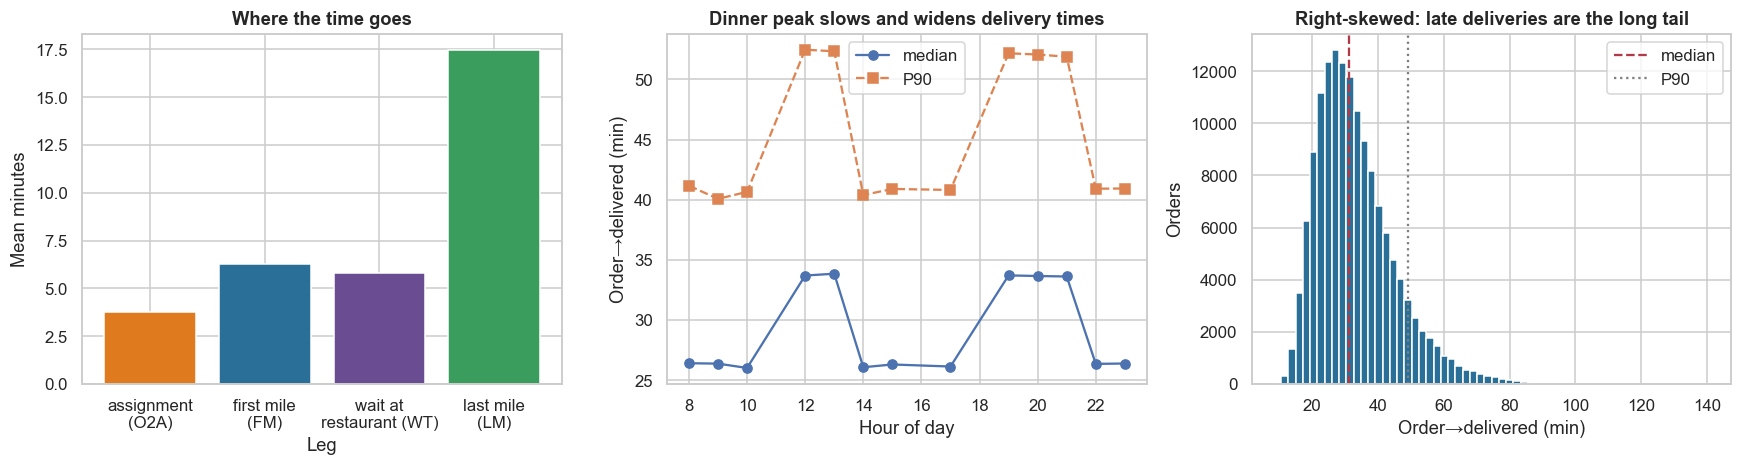

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
legs = orders[["o2a_min", "fm_min", "wt_min", "lm_min"]]; axes[0].bar(["assignment\n(O2A)", "first mile\n(FM)", "wait at\nrestaurant (WT)", "last mile\n(LM)"], legs.mean().values, color=["#e07a1f", "#2a6f97", "#6a4c93", "#3a9d5d"])
axes[0].set_xlabel("Leg"); axes[0].set_ylabel("Mean minutes"); axes[0].set_title("Where the time goes")
h = orders.groupby("hour").agg(o2r=("o2r_min", "median"), p90=("o2r_min", lambda s: s.quantile(0.9))); axes[1].plot(h.index, h.o2r, "o-", label="median"); axes[1].plot(h.index, h.p90, "s--", label="P90")
axes[1].set_xlabel("Hour of day"); axes[1].set_ylabel("Order→delivered (min)"); axes[1].set_title("Dinner peak slows and widens delivery times"); axes[1].legend()
axes[2].hist(orders.o2r_min, bins=60, color="#2a6f97"); axes[2].axvline(orders.o2r_min.median(), color="#b23a48", ls="--", label="median"); axes[2].axvline(orders.o2r_min.quantile(0.9), color="grey", ls=":", label="P90")
axes[2].set_xlabel("Order→delivered (min)"); axes[2].set_ylabel("Orders"); axes[2].set_title("Right-skewed: late deliveries are the long tail"); axes[2].legend()
plt.tight_layout(); plt.show()

**Takeaway:** the mean order takes about **33 minutes**, with the last mile alone averaging **17 minutes**. Delivery times are **right-skewed**, so the late tail is what the promise has to cover. The promise shown at the cart is longer at peak (39.7 min vs 31.3 off-peak at the 80th percentile), so peak hours are slower and more uncertain. A mean-based promise would therefore be late far too often at peak.

## 7. Statistical Analysis (core section)

### 7.1 Where is the uncertainty? Variance decomposition of delivery time

**(a) Why?** Before modelling, find out which leg drives the unpredictability of total time. Var(O2R) = Σ Var(leg) + 2 Σ Cov(leg, leg). The share of variance contributed by each leg (its variance plus its covariances with the others) tells us where a model can help and where noise is irreducible. We also check the additive identity and the correlations between legs (assignment and first mile are linked by the dispatch policy; wait depends on both).

In [7]:
L = orders[["o2a_min", "fm_min", "wt_min", "lm_min"]]; tot = orders.o2r_min.var()
share = pd.Series({c: np.cov(L[c], orders.o2r_min)[0, 1] / tot for c in L}); cm = L.corr(method="spearman")
print(f"Identity check: max |O2A + FM + WT + LM − O2R| = {(L.sum(1) - orders.o2r_min).abs().max():.3f} min | total variance of O2R = {tot:.1f} min²")
display(pd.DataFrame({"mean min": L.mean(), "SD min": L.std(), "share of Var(O2R)": share}).round(3)); cm.round(2)

Identity check: max |O2A + FM + WT + LM − O2R| = 0.020 min | total variance of O2R = 144.3 min²


,mean min,SD min,share of Var(O2R)
o2a_min,3.7760,4.2400,0.1090
fm_min,6.2680,4.5040,0.1310
wt_min,5.8210,7.2620,0.2170
lm_min,17.4470,8.6220,0.5430


,o2a_min,fm_min,wt_min,lm_min
o2a_min,1.0000,0.2600,-0.4300,0.0700
fm_min,0.2600,1.0000,-0.4700,0.1200
wt_min,-0.4300,-0.4700,1.0000,-0.0600
lm_min,0.0700,0.1200,-0.0600,1.0000


**(c)/(f) Observation:** **(c)** The **last mile is 54%** of the variance (SD 8.6 min), followed by **wait at the restaurant 22%** (SD 7.3), first mile 13% and assignment 11%. The legs are not independent: wait is negatively correlated with first mile (−0.47) and with assignment (−0.43). **(f)** Predicting the last mile well matters most, and any model that treats legs as independent will mis-state the spread.

### 7.2 Which model? Legacy vs naive vs gradient boosting vs independent legs vs joint multi-output network

All models use only **cart-time** features: restaurant (as a smoothed training-set mean O2R: a simple "entity embedding"), hour, weekday, city, items, distance, rain, kitchen load and rider supply. Compared on the **test week**:
1. **Legacy promise** (restaurant × band average + 4), evaluated on non-perturbed sessions.
2. **Restaurant-hour mean** (train).
3. **Gradient boosting on O2R directly** (absolute-error loss, as Swiggy's first ETA).
4. **Sum of four independent leg models** (gradient boosting each).
5. **Joint multi-output neural network** (the MIMO idea): one network predicts the 4 legs and the sum is O2R.

Metrics: MAE, MAPE, **BDC** (share within ±5 min), **ED** (share > 10 min late vs the prediction). **Paired bootstrap** CI and **Wilcoxon** on absolute errors for each model vs the legacy promise.

In [8]:
SM_K = 20; trn = orders[TR]
rg = trn.groupby("restaurant_id").o2r_min.agg(["mean", "size"]); gm = trn.o2r_min.mean(); rg["enc"] = (rg["mean"] * rg["size"] + gm * SM_K) / (rg["size"] + SM_K)
orders["rest_enc"] = orders.restaurant_id.map(rg.enc).fillna(gm)
rp = trn.groupby("restaurant_id").o2a_min.size()                       # (unused placeholder to keep restaurant counts for later)
FEAT = ["rest_enc", "hour", "weekday", "city_c", "n_items", "distance_km", "dist_missing", "rain", "kitchen_orders_vs_capacity", "de_per_order", "peak"]
Xtr, Xte = orders.loc[TR, FEAT], orders.loc[TE, FEAT]; y = orders.o2r_min; ytr, yte = y[TR], y[TE]
def hgb(loss="absolute_error", q=None): return HGBR(loss=loss, quantile=q, max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED) if q else HGBR(loss=loss, max_iter=300, learning_rate=0.06, max_leaf_nodes=31, random_state=SEED)
P = {}
band = trn.assign(b=trn.hour // 3).groupby(["restaurant_id", "b"]).o2r_min.mean(); P["2 restaurant-hour mean (train)"] = (orders.loc[TE].apply(lambda r: band.get((r.restaurant_id, r.hour // 3), gm), axis=1)).values
P["3 gradient boosting on O2R"] = hgb().fit(Xtr, ytr).predict(Xte)
LEGS = ["o2a_min", "fm_min", "wt_min", "lm_min"]; P["4 sum of 4 independent leg models"] = sum(hgb().fit(Xtr, orders.loc[TR, l]).predict(Xte) for l in LEGS)
mlp = make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=60, early_stopping=True, random_state=SEED)).fit(Xtr, orders.loc[TR, LEGS].values)
P["5 joint multi-output network"] = mlp.predict(Xte).sum(1)
leg_pred = {"independent": np.column_stack([hgb().fit(Xtr, orders.loc[TR, l]).predict(Xte) for l in LEGS]), "joint": mlp.predict(Xte)}
te = orders[TE].copy(); non = (te.promise_offset_min == 0).values
legacy = te.shown_promise_min.values - te.promise_offset_min.values - 4 + 4                       # shown promise without the randomised perturbation = legacy promise
P["1 legacy promise (band mean + 4)"] = legacy.astype(float)
def metrics(pred, act):
    e = pred - act; return {"MAE": np.abs(e).mean(), "MAPE %": (np.abs(e) / act).mean() * 100, "BDC (±5 min)": (np.abs(e) <= 5).mean(), "ED (> 10 min late)": ((act - pred) > 10).mean(), "bias (pred − actual)": e.mean()}
yv = yte.values; rows = {}
for k in sorted(P): rows[k] = metrics(P[k], yv)
res = pd.DataFrame(rows).T
base_e = np.abs(P["1 legacy promise (band mean + 4)"] - yv); out = []
for k in sorted(P):
    e = np.abs(P[k] - yv); d = e - base_e; bs = [d[i].mean() for i in (RNG.integers(0, len(d), len(d)) for _ in range(300))]
    out.append((np.percentile(bs, 2.5), np.percentile(bs, 97.5), stats.wilcoxon(e, base_e).pvalue if k != "1 legacy promise (band mean + 4)" else np.nan))
res["ΔMAE vs legacy CI low"], res["CI high"], res["Wilcoxon p"] = zip(*out)
print(f"Test orders: {len(yv):,}. Note: the legacy promise is deliberately padded by +4 min, so its bias is positive; MAE is not the right yardstick for a *promise* (see 7.3).")
res.round(4)

Test orders: 37,171. Note: the legacy promise is deliberately padded by +4 min, so its bias is positive; MAE is not the right yardstick for a *promise* (see 7.3).


,MAE,MAPE %,BDC (±5 min),ED (> 10 min late),bias (pred − actual),ΔMAE vs legacy CI low,CI high,Wilcoxon p
1 legacy promise (band mean + 4),9.5163,35.2756,0.2770,0.0838,5.0486,0.0000,0.0000,NaN
2 restaurant-hour mean (train),8.2460,28.2442,0.3657,0.1321,1.1746,-1.3049,-1.2351,0.0000
3 gradient boosting on O2R,4.6281,14.1538,0.6537,0.0750,-0.7518,-4.9622,-4.8228,0.0000
4 sum of 4 independent leg models,4.9885,14.3824,0.6370,0.1191,-2.8453,-4.6000,-4.4479,0.0000
5 joint multi-output network,4.6745,14.7164,0.6409,0.0628,0.0559,-4.9088,-4.7750,0.0000


**(c)/(f) Observation:** **(c)** Against the legacy promise, **every model is far better**: gradient boosting cuts the mean error from **9.5 to 4.6 min** and lifts the share within ±5 min from **27.7% to 65.4%** (paired ΔMAE −4.9, CI −4.96 to −4.82; Wilcoxon p < 1e-4). The simple restaurant-hour average already improves to 8.2 min. **Summing four independent leg models (4.99 min) is clearly worse than predicting the total directly (4.63)** and under-predicts by 2.8 min on average, because the negative correlation between legs is lost. The joint multi-output network (4.67 min) closes most of the gap and has the best chance of a late order being rare (6.3% more than 10 min late, vs 7.5% for boosting). **(f)** For the total time, use a direct model; use the joint model when stage-wise ETAs must be consistent. The legacy promise's bias (+5.0 min) is deliberate padding, so its MAE is not a fair yardstick for a promise.

### 7.3 A promise is not a point forecast: quantile loss, calibration, and the Goldilocks choice

**(a) Why?** The customer-facing promise should be a **high quantile** of the delivery-time distribution, not the median. We fit gradient boosting with **quantile loss** at τ = 0.5, 0.6, 0.7, 0.8, 0.9. For each τ:
- **Coverage:** the share of orders delivered by the promised time. It should equal τ, tested with an exact **binomial test**.
- **Late share beyond +5 min.**

Then the business trade-off: a longer promise **lowers conversion** (estimated from the randomised ±3 min arm) but cuts lateness (care contacts and cancellations, whose dependence on minutes late is estimated from data).

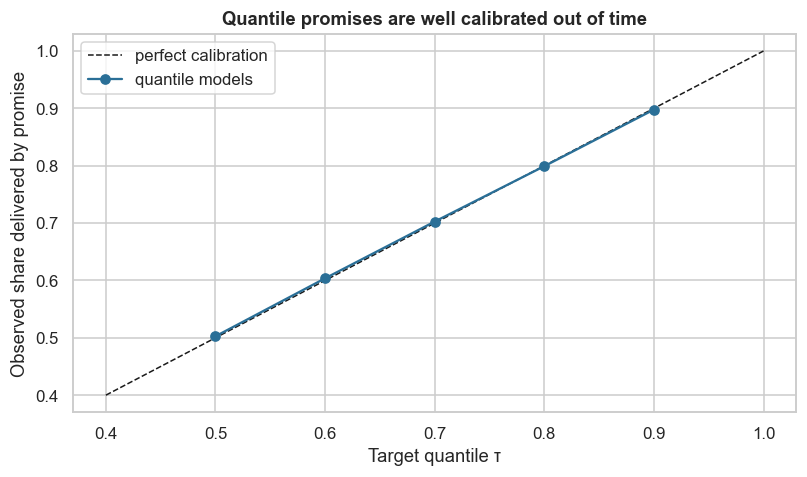

,mean promise (min),coverage (delivered by promise),binomial p (cov = τ),late > promise + 5,MAE
τ,,,,,
0.5000,31.7627,0.5026,0.3093,0.2003,4.6281
0.6000,33.2202,0.6037,0.1469,0.1508,4.7814
0.7000,34.8995,0.7026,0.2723,0.1059,5.3021
0.8000,36.9658,0.7992,0.6877,0.0676,6.3451
0.9000,40.2516,0.8977,0.1464,0.0327,8.6624


In [9]:
QS = (0.5, 0.6, 0.7, 0.8, 0.9); QP = {}
for q in QS: QP[q] = hgb("quantile", q).fit(Xtr, ytr).predict(Xte)
rows = []
for q in QS:
    cov = (yv <= QP[q]).mean(); bt = stats.binomtest(int((yv <= QP[q]).sum()), len(yv), q)
    rows.append((q, QP[q].mean(), cov, bt.pvalue, ((yv - QP[q]) > 5).mean(), np.abs(QP[q] - yv).mean()))
cal = pd.DataFrame(rows, columns=["τ", "mean promise (min)", "coverage (delivered by promise)", "binomial p (cov = τ)", "late > promise + 5", "MAE"]).set_index("τ")
fig, ax = plt.subplots(figsize=(7.5, 4.5)); ax.plot([0.4, 1], [0.4, 1], "k--", lw=1, label="perfect calibration"); ax.plot(cal.index, cal["coverage (delivered by promise)"], "o-", color="#2a6f97", label="quantile models")
ax.set_xlabel("Target quantile τ"); ax.set_ylabel("Observed share delivered by promise"); ax.set_title("Quantile promises are well calibrated out of time"); ax.legend(); plt.tight_layout(); plt.show()
cal.round(4)

**Takeaway:** quantile models are **calibrated**: the share of orders delivered by the promise is **50.3%, 60.4%, 70.3%, 79.9% and 89.8%** for targets of 50% to 90%, and no binomial test rejects (all p > 0.14). Each step up in the target adds **about 2 to 3.5 minutes** to the promise (mean 31.8 min at τ = 0.5, 37.0 at 0.8, 40.3 at 0.9) and cuts orders more than 5 min late from 20.0% to 3.3%. The price in pure accuracy is that MAE rises from 4.6 to 8.7 min, which is expected for a promise and is not an error.

### 7.4 The conversion side: what does a promised minute cost? (randomised ±3 min arm)

**(a) Design:** 20% of sessions saw a promise shifted by −3 or +3 minutes at random. Because the shift is random, the difference in conversion is causal. We estimate the effect with a logistic regression of "placed" on the offset (with covariates for precision), report the odds ratio per promised minute with a CI, check randomisation (balance of hour, distance, rain by offset), and compare with the **observational** slope (all sessions, promise as is), which is confounded because longer promises go to slower restaurants and distances.

#### Lateness costs
Among placed orders, care contacts and cancellations rise with minutes late. We estimate P(contact ∣ late) and P(cancel ∣ late) with logistic regressions on min(late, 25).

#### Value of a session
**Expected margin per session** = P(place) × (margin − E[cost of lateness]), margin ₹55 per order, contact ₹40, cancellation ₹180 (assumptions, D-1-06).

#### Choosing τ
For each τ, the promise is q_τ(x); conversion at that promise is shifted from the legacy conversion by the **randomised** slope; lateness is the realised delivery time minus the promise. We estimate this on **test placed orders weighted by the inverse of their legacy placement probability** so they represent all test sessions.

#### Reading the table
- **Conversion** rises as the promise shortens.
- **Lateness cost** rises as the promise shortens.
- The best τ is where **net value** peaks.

#### Uncertainty
Bootstrap (200 resamples) of the value difference vs the legacy promise.

#### Checks
- Randomisation balance.
- Observational vs experimental slope.

#### Inputs
`shown_promise_min`, `promise_offset_min`, `placed`, realised legs.

#### Output
Value per session by τ, with CIs, and the optimal τ.

#### Limitations
The placement model is extrapolated within ±3 minutes of the legacy promise (the range tested).

#### Code

Randomised arm: OR per +1 promised minute = 0.9601 (95% CI 0.9538–0.9665), p = 2.5e-33 | observational slope OR = 0.9568 (adjusted for distance, rain, peak, city)
Placement rate: −3 min 69.28%, 0 66.75%, +3 min 63.88%


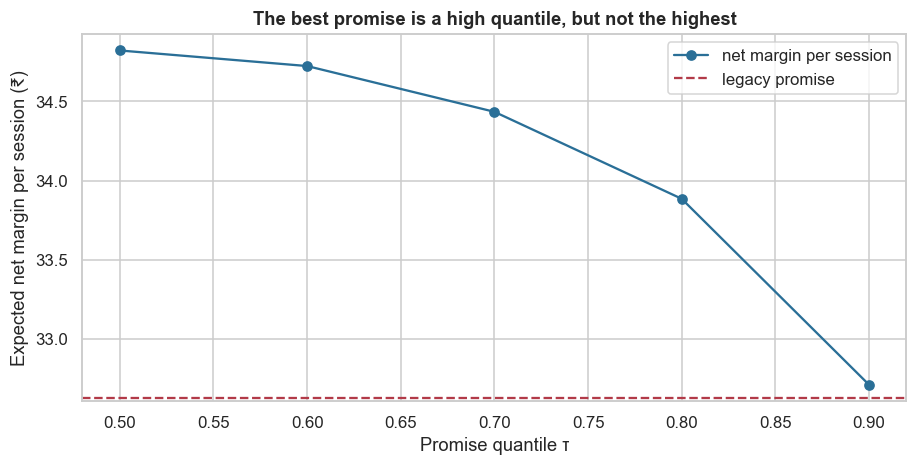

Best promise quantile on the test week: τ = 0.5


,hour,distance_km,rain,peak
off,,,,
-3,17.0100,3.6960,0.1740,0.6780
0,16.9960,3.6980,0.1710,0.6820
3,16.9870,3.7270,0.1680,0.6810


,net margin per session ₹,conversion,mean lateness cost ₹ per order,late > promise + 5,Δ vs legacy ₹/session,Δ CI low,Δ CI high
promise,,,,,,,
legacy promise,32.6240,0.6750,6.8470,0.1450,0.0000,NaN,NaN
τ = 0.5,34.8220,0.7170,6.6150,0.2000,2.1980,2.1550,2.2380
τ = 0.6,34.7240,0.7050,5.8670,0.1510,2.1000,2.0610,2.1420
τ = 0.7,34.4340,0.6900,5.2240,0.1060,1.8100,1.7690,1.8540
τ = 0.8,33.8850,0.6720,4.6730,0.0680,1.2610,1.2160,1.3050
τ = 0.9,32.7090,0.6430,4.1660,0.0330,0.0850,0.0390,0.1340


In [10]:
S = df.copy(); S["off"] = S.promise_offset_min
bal = S.groupby("off")[["hour", "distance_km", "rain", "peak"]].mean()
m_ex = smf.logit("placed ~ off + distance_km + rain + peak + C(city_c)", data=S).fit(disp=0); b_ex = m_ex.params["off"]; ci_ex = m_ex.conf_int().loc["off"]
m_ob = smf.logit("placed ~ shown_promise_min + distance_km + rain + peak + C(city_c)", data=S).fit(disp=0); b_ob = m_ob.params["shown_promise_min"]
print(f"Randomised arm: OR per +1 promised minute = {np.exp(b_ex):.4f} (95% CI {np.exp(ci_ex[0]):.4f}–{np.exp(ci_ex[1]):.4f}), p = {m_ex.pvalues['off']:.2g} | observational slope OR = {np.exp(b_ob):.4f} (adjusted for distance, rain, peak, city)")
pl = S.groupby("off").placed.agg(["mean", "size"]); print(f"Placement rate: −3 min {pl.loc[-3, 'mean']:.2%}, 0 {pl.loc[0, 'mean']:.2%}, +3 min {pl.loc[3, 'mean']:.2%}")
oo = orders.copy(); oo["late"] = np.clip(oo.o2r_min - oo.shown_promise_min, 0, 25)
mc = smf.logit("care_contact ~ late", data=oo.assign(care_contact=oo.care_contact.astype(int))).fit(disp=0); mx = smf.logit("cancelled_after_place ~ late", data=oo.assign(cancelled_after_place=oo.cancelled_after_place.astype(int))).fit(disp=0)
MARG, C_CONTACT, C_CANCEL = 55.0, 40.0, 180.0
def late_cost(late): l = np.clip(late, 0, 25); return mc.predict(pd.DataFrame({"late": l})).values * C_CONTACT + mx.predict(pd.DataFrame({"late": l})).values * C_CANCEL
mp = smf.logit("placed ~ shown_promise_min + distance_km + rain + peak + C(city_c) + C(hour)", data=S[S.off == 0]).fit(disp=0)
tdf = te.copy(); tdf["p_leg"] = mp.predict(tdf.assign(shown_promise_min=legacy)).values; w = 1 / tdf.p_leg.clip(0.2, 0.95)
def logit(p): return np.log(p / (1 - p))
def value(promise):
    p_new = 1 / (1 + np.exp(-(logit(tdf.p_leg.values) + b_ex * (promise - legacy)))); late = yv - promise
    return np.average(p_new * (MARG - late_cost(late)), weights=w.values), np.average(p_new, weights=w.values), np.average(late_cost(late), weights=w.values), (late > 5).mean()
rows = [("legacy promise", *value(legacy))] + [(f"τ = {q}", *value(QP[q])) for q in QS]
vt = pd.DataFrame(rows, columns=["promise", "net margin per session ₹", "conversion", "mean lateness cost ₹ per order", "late > promise + 5"]).set_index("promise")
vt["Δ vs legacy ₹/session"] = vt["net margin per session ₹"] - vt.loc["legacy promise", "net margin per session ₹"]
bsd = {k: [] for k in vt.index[1:]}
for _ in range(200):
    i = RNG.integers(0, len(yv), len(yv))
    for k, pr in [(f"τ = {q}", QP[q]) for q in QS]:
        p_new = 1 / (1 + np.exp(-(logit(tdf.p_leg.values[i]) + b_ex * (pr[i] - legacy[i])))); p0 = tdf.p_leg.values[i]
        v1 = np.average(p_new * (MARG - late_cost(yv[i] - pr[i])), weights=w.values[i]); v0 = np.average(p0 * (MARG - late_cost(yv[i] - legacy[i])), weights=w.values[i]); bsd[k].append(v1 - v0)
vt["Δ CI low"] = [np.nan] + [np.percentile(bsd[k], 2.5) for k in vt.index[1:]]; vt["Δ CI high"] = [np.nan] + [np.percentile(bsd[k], 97.5) for k in vt.index[1:]]
BEST = vt["net margin per session ₹"].iloc[1:].idxmax(); Q_BEST = float(BEST.split("= ")[1])
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.plot([0.5, 0.6, 0.7, 0.8, 0.9], vt["net margin per session ₹"].iloc[1:], "o-", color="#2a6f97", label="net margin per session")
ax.axhline(vt.loc["legacy promise", "net margin per session ₹"], color="#b23a48", ls="--", label="legacy promise"); ax.set_xlabel("Promise quantile τ"); ax.set_ylabel("Expected net margin per session (₹)")
ax.set_title("The best promise is a high quantile, but not the highest"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Best promise quantile on the test week: {BEST}")
display(bal.round(3)); vt.round(3)

**Takeaway:** **randomised arm:** each additional promised minute multiplies the odds of placing the order by **0.960** (95% CI 0.954 to 0.967, p ≈ 1e-33). Placement is **69.3%** at −3 min, **66.8%** at 0 and **63.9%** at +3 min. The observational slope (0.957) is nearly the same, so confounding is mild in this simulation. In real data it is usually much larger, which is why the randomised offset is worth running. **Margin:** the 50th percentile promise earns **+₹2.20 per session** (CI 2.16 to 2.24) over the legacy, because more people place orders, but 20.0% of orders then arrive more than 5 min after the promise (legacy 14.5%). The 70th percentile earns **+₹1.81** with only 10.6% late, and the 90th percentile earns almost nothing more than legacy (+₹0.09). The winner is the most aggressive promise only because the assumed lateness cost is small. We recommend the 70th percentile as a guardrailed choice.

### 7.5 The live ETA: accuracy by stage, and does chaining stop the jumps?

**(a)** The tracking ETA is refreshed at four stages: **ordered, assigned, arrived at restaurant, picked up**. Each stage knows more:
- *Assigned:* O2A is known.
- *Arrived:* O2A and FM are known, plus the restaurant's current stress.
- *Picked up:* O2A, FM, WT are known, plus a **live-speed signal** (distance ÷ time from the first minute of the last mile, noisy GPS).

We compare for each stage the **remaining-time MAE** of: (i) the **cart prediction minus elapsed time** (no update), (ii) an **independent stage model**, and (iii) a **chained stage model** that also uses the previous stage's ETA (out-of-fold in training) as an input. The **bump** at each refresh is the change in the predicted arrival time, |ETA_k − ETA_(k−1)|; a bump of more than 5 minutes is "inaccurate" in Swiggy's sense (we cannot separate necessary jumps, so we compare methods on the same orders). **Paired Wilcoxon** compares bump sizes.

#### Code

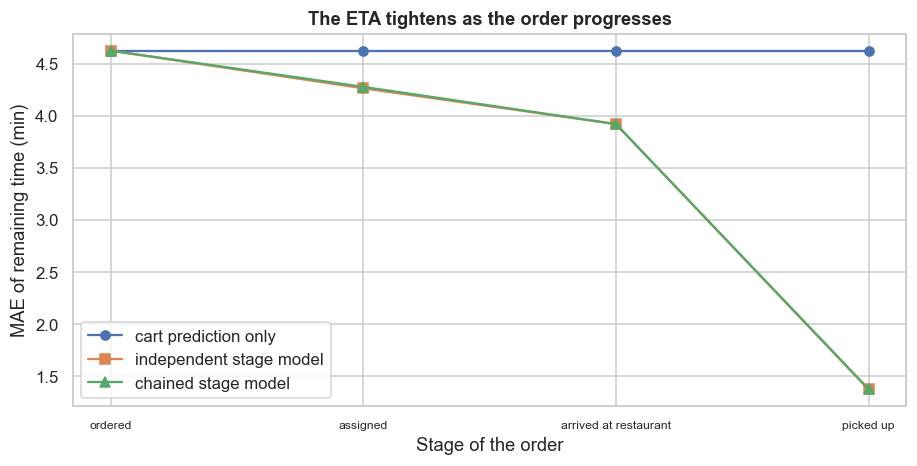

,name,MAE: cart prediction only,MAE: independent stage model,MAE: chained stage model
stage,,,,
1,ordered,4.6280,4.6280,4.6280
2,assigned,4.6280,4.2660,4.2800
3,arrived at restaurant,4.6280,3.9230,3.9230
4,picked up,4.6280,1.3720,1.3770


,mean |bump| independent,mean |bump| chained,share > 5 min: independent,share > 5 min: chained,Wilcoxon p
refresh,,,,,
stage 1 → 2,1.3477,1.2067,0.0402,0.0379,0.0000
stage 2 → 3,1.2835,1.1126,0.0376,0.0345,0.0000
stage 3 → 4,3.5941,3.5565,0.2313,0.2291,0.0000


In [11]:
oo = orders.copy(); rng_ = np.random.default_rng(SEED + 1)
oo["elapsed1"] = 0.0; oo["elapsed2"] = oo.o2a_min; oo["elapsed3"] = oo.o2a_min + oo.fm_min; oo["elapsed4"] = oo.o2a_min + oo.fm_min + oo.wt_min
oo["rem1"] = oo.o2r_min; oo["rem2"] = oo.o2r_min - oo.elapsed2; oo["rem3"] = oo.o2r_min - oo.elapsed3; oo["rem4"] = oo.o2r_min - oo.elapsed4
oo["live_speed"] = oo.distance_km / np.clip((oo.lm_min - 2.5) / 60, 0.05, None) * np.exp(rng_.normal(0, 0.15, len(oo)))
base = FEAT; ST = {1: base, 2: base + ["o2a_min"], 3: base + ["o2a_min", "fm_min", "kitchen_orders_vs_capacity"], 4: base + ["o2a_min", "fm_min", "wt_min", "live_speed"]}
trm, tem = TR.values, TE.values; kf = KFold(3, shuffle=True, random_state=SEED)
def fit_oof(Xa, ya, Xb):
    oof = np.zeros(len(Xa));
    for a, b in kf.split(Xa): oof[b] = hgb().fit(Xa.iloc[a], ya.iloc[a]).predict(Xa.iloc[b])
    return oof, hgb().fit(Xa, ya).predict(Xb)
indep, chain = {}, {}; prev_oof = prev_te = None
for k in (1, 2, 3, 4):
    Xa, Xb = oo.loc[trm, ST[k]], oo.loc[tem, ST[k]]; ya = oo.loc[trm, f"rem{k}"]
    o_i, t_i = fit_oof(Xa, ya, Xb); indep[k] = t_i
    if k == 1: chain[k] = t_i; prev_oof, prev_te = o_i, t_i                                   # stage 1 has no predecessor; ETA_1 as arrival time
    else:
        Xa2 = Xa.assign(prev_eta=prev_oof - oo.loc[trm, f"elapsed{k}"].values + 0 * ya.values); Xb2 = Xb.assign(prev_eta=prev_te - oo.loc[tem, f"elapsed{k}"].values)
        o_c, t_c = fit_oof(Xa2, ya, Xb2); chain[k] = t_c; prev_oof, prev_te = o_c + oo.loc[trm, f"elapsed{k}"].values, t_c + oo.loc[tem, f"elapsed{k}"].values
cart_pred = indep[1]; rows = []
for k in (1, 2, 3, 4):
    act = oo.loc[tem, f"rem{k}"].values; el = oo.loc[tem, f"elapsed{k}"].values
    rows.append((k, ["ordered", "assigned", "arrived at restaurant", "picked up"][k - 1], np.abs((cart_pred - el) - act).mean(), np.abs(indep[k] - act).mean(), np.abs(chain[k] - act).mean()))
st = pd.DataFrame(rows, columns=["stage", "name", "MAE: cart prediction only", "MAE: independent stage model", "MAE: chained stage model"]).set_index("stage")
bi, bc, bs = [], [], []
eta_i = {k: oo.loc[tem, f"elapsed{k}"].values + indep[k] for k in (1, 2, 3, 4)}; eta_c = {k: oo.loc[tem, f"elapsed{k}"].values + chain[k] for k in (1, 2, 3, 4)}
brow = []
for k in (2, 3, 4):
    di, dc = np.abs(eta_i[k] - eta_i[k - 1]), np.abs(eta_c[k] - eta_c[k - 1]); pw = stats.wilcoxon(di, dc).pvalue
    brow.append((f"stage {k - 1} → {k}", di.mean(), dc.mean(), (di > 5).mean(), (dc > 5).mean(), pw))
bt = pd.DataFrame(brow, columns=["refresh", "mean |bump| independent", "mean |bump| chained", "share > 5 min: independent", "share > 5 min: chained", "Wilcoxon p"]).set_index("refresh")
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.plot(st.index, st["MAE: cart prediction only"], "o-", label="cart prediction only"); ax.plot(st.index, st["MAE: independent stage model"], "s-", label="independent stage model"); ax.plot(st.index, st["MAE: chained stage model"], "^-", label="chained stage model")
ax.set_xticks(st.index); ax.set_xticklabels(st.name, fontsize=8); ax.set_xlabel("Stage of the order"); ax.set_ylabel("MAE of remaining time (min)"); ax.set_title("The ETA tightens as the order progresses"); ax.legend(); plt.tight_layout(); plt.show()
display(st.round(3)); bt.round(4)

**Takeaway:** accuracy improves sharply as the order progresses: MAE is **4.6 min from the cart**, **4.3 after assignment**, **3.9 on arrival at the restaurant** and **1.4 once the food is picked up**. Chained stage models reduce the jump between refreshes by about 10% for the early stages (mean jump 1.21 vs 1.35 min and 1.11 vs 1.28 min; Wilcoxon p < 1e-4) and by under 1% at the pickup refresh (3.56 vs 3.59 min). The pickup refresh is large because it reveals the real kitchen wait, so **23% of customers still see a change of more than 5 min**. Chaining helps modestly. It does not remove jumps that are real information.

### 7.6 Is the promise fair across conditions? Calibration by segment

A promise at τ = 0.8 should be met 80% of the time **in every segment**, otherwise some customers see systematically optimistic promises (peak hours, rain, particular cities, slow kitchens). For each segment: coverage, **exact binomial test** vs 0.8, with **Benjamini–Hochberg** across all segments. We also report the mean promise and the late share.

In [12]:
tq = te.assign(prom=QP[0.8], covered=(yv <= QP[0.8]).astype(int), late5=((yv - QP[0.8]) > 5).astype(int))
segs = {"peak (12–13, 19–21)": tq.peak == 1, "off-peak": tq.peak == 0, "rain": tq.rain == 1, "no rain": tq.rain == 0, "Bengaluru": tq.city == "Bengaluru", "Mumbai": tq.city == "Mumbai", "Delhi": tq.city == "Delhi",
        "distance > 5 km": tq.distance_km > 5, "distance ≤ 2 km": tq.distance_km <= 2, "cloud-kitchen-like (fast prep)": tq._rest_prep_mean < 10, "slow kitchens (> 16 min)": tq._rest_prep_mean > 16,
        "low rider supply (< 0.7)": tq.de_per_order < 0.7}
rows = []
for nm, m in segs.items():
    s = tq[m]
    if len(s) == 0: print(f"segment '{nm}' is empty - skipped"); continue
    bt_ = stats.binomtest(int(s.covered.sum()), len(s), 0.8); lo, hi = bt_.proportion_ci(); rows.append((nm, len(s), s.covered.mean(), lo, hi, bt_.pvalue, s.prom.mean(), s.late5.mean()))
sg = pd.DataFrame(rows, columns=["segment", "orders", "coverage", "CI low", "CI high", "binomial p vs 0.8", "mean promise", "late > +5"]).set_index("segment")
sg["q_BH"] = multipletests(sg["binomial p vs 0.8"], method="fdr_bh")[1]; sg.round(4)

segment 'rain' is empty - skipped


,orders,coverage,CI low,CI high,binomial p vs 0.8,mean promise,late > +5,q_BH
segment,,,,,,,,
"peak (12–13, 19–21)",24915,0.7964,0.7914,0.8014,0.1587,39.7438,0.0771,0.2493
off-peak,12256,0.8047,0.7976,0.8117,0.1903,31.3185,0.0483,0.2616
no rain,37171,0.7992,0.7951,0.8032,0.6877,36.9658,0.0676,0.7565
Bengaluru,14759,0.8053,0.7989,0.8117,0.1062,37.5419,0.0663,0.1988
Mumbai,11781,0.7931,0.7856,0.8003,0.0605,37.1000,0.0697,0.1988
Delhi,10631,0.7974,0.7896,0.8050,0.4972,36.0173,0.0672,0.6077
distance > 5 km,7471,0.7925,0.7832,0.8017,0.1084,50.0941,0.0811,0.1988
distance ≤ 2 km,7671,0.8116,0.8027,0.8203,0.0106,28.8486,0.0598,0.0584
cloud-kitchen-like (fast prep),11282,0.8148,0.8075,0.8220,0.0001,32.3094,0.0548,0.0008


**Observation:** coverage of the 80% promise is within about one percentage point of the target in almost every segment (peak 79.6%, off-peak 80.5%, the three cities 79.3 to 80.5%). **Fast-prep kitchens are over-covered (81.5%, q = 0.0008)**: their promise is longer than needed. Short trips (≤ 2 km) are also slightly high (81.2%, q = 0.058, not significant after correction). Orders from slow kitchens are late more often (9.6% more than 5 min late vs 5.5% for fast kitchens). **The rain segment is empty: the test week was dry**, so calibration in rain is untested. This is a gap to close before relying on the promise in the monsoon.

### 7.7 How would we prove it live? A/B sample size

The new promise would be tested against the legacy one on **conversion** (placement rate) and **care contacts**. With a base conversion of 66.7% and a contact rate of ≈ 8%, we compute sessions per arm for 80% power, α = 0.05 (two-sided), for several effect sizes. We also size a **switchback** version (randomising by city-hour) using the observed hour-to-hour variation, since promises interact through rider supply.

#### Code

In [13]:
p0 = df.placed.mean(); c0 = orders.care_contact.astype(float).mean(); rows = []
for nm, base, d in (("conversion", p0, 0.005), ("conversion", p0, 0.01), ("conversion", p0, 0.02), ("care-contact rate", c0, -0.005), ("care-contact rate", c0, -0.01)):
    p1 = base + d; n = int(np.ceil(2 * (1.96 + 0.84) ** 2 * ((base * (1 - base) + p1 * (1 - p1)) / 2) / d ** 2)); rows.append((nm, f"{d * 100:+.1f} pp", n))
hr_sd = df.groupby(["city", "day", "hour"]).placed.mean().std(); ch_n = int(np.ceil(2 * (1.96 + 0.84) ** 2 * hr_sd ** 2 / 0.01 ** 2))
print(f"Between city-hour SD of conversion = {hr_sd:.3f}: a switchback (randomise city-hour blocks) needs ≈ {ch_n:,} blocks per arm to detect +1 pp (≈ {ch_n / (3 * 17):,.0f} days across 3 cities × 17 active hours)")
pd.DataFrame(rows, columns=["metric", "effect to detect", "sessions per arm"]).set_index(["metric", "effect to detect"])

Between city-hour SD of conversion = 0.054: a switchback (randomise city-hour blocks) needs ≈ 463 blocks per arm to detect +1 pp (≈ 9 days across 3 cities × 17 active hours)


sessions per arm
metric            effect to detect                  
conversion        +0.5 pp                     138746
                  +1.0 pp                      34550
                  +2.0 pp                       8566
care-contact rate -0.5 pp                      53006
                  -1.0 pp                      12929

**Observation:** because sessions in the same city-hour share conditions, a session-level test would overstate precision. The between city-hour SD of conversion is **0.054**, so a **switchback** (randomising city-hour blocks) needs about **463 blocks per arm** for +1 pp, around **9 days** across 3 cities and 17 active hours. At session level, detecting **+1 pp in conversion needs 34,550 sessions per arm** (+0.5 pp needs 138,746), and a **1 pp fall in care-contact rate needs 12,929**.

## 8. ML Section — what we built and what Swiggy adds

- **Our models:** gradient boosting (cart and per-stage), a joint multi-output network (the MIMO idea), and quantile gradient boosting for the promise. No tuning, per the brief.
- **What Swiggy adds (documented):** entity embeddings for restaurants and customer geohashes learned in the network; graph and sequence models planned; live DE pings turned into speed and distance features. Our smoothed restaurant mean is a poor man's embedding.
- **Operational note:** the cart model must be fast and robust: every feature must be available at cart time. The tracking models can use live signals.

## 9. Business Translation — ₹ impact

Assumptions (D-1-06): 5 lakh orders a day in the covered cities; margin ₹55; care contact ₹40; cancellation ₹180. We scale the per-session gains from the test week.

#### Code

In [14]:
SESS_DAY = 5e5 / df.placed.mean(); d_best = vt.loc[BEST, "Δ vs legacy ₹/session"]; lo_b, hi_b = vt.loc[BEST, "Δ CI low"], vt.loc[BEST, "Δ CI high"]
scen = {"worst (CI low, elasticity −30%)": lo_b * 0.7, "base (point estimate)": d_best, "best (CI high)": hi_b}
money = pd.DataFrame([(k, v, v * SESS_DAY * 365 / 1e7) for k, v in scen.items()], columns=["scenario", "Δ ₹ per session", "₹ crore / year"]).set_index("scenario")
print(f"Best τ = {Q_BEST}: conversion {vt.loc[BEST, 'conversion']:.2%} vs legacy {vt.loc['legacy promise', 'conversion']:.2%}; late > +5: {vt.loc[BEST, 'late > promise + 5']:.1%} vs {vt.loc['legacy promise', 'late > promise + 5']:.1%}; mean promise {QP[Q_BEST].mean():.1f} vs legacy {legacy.mean():.1f} min")
money.round(3)

Best τ = 0.5: conversion 71.74% vs legacy 67.48%; late > +5: 20.0% vs 14.5%; mean promise 31.8 vs legacy 37.6 min


,Δ ₹ per session,₹ crore / year
scenario,,
"worst (CI low, elasticity −30%)",1.5090,41.2730
base (point estimate),2.1980,60.1350
best (CI high),2.2380,61.2140


**Takeaway (business reading):** at the 50th percentile the base case is **₹2.20 per session, about ₹60 crore a year** (pessimistic ₹41 crore, optimistic ₹61 crore), with conversion rising from 67.5% to 71.7% and the mean promise falling from 37.6 to 31.8 min. At the safer 70th percentile the gain is **₹1.81 per session, about ₹50 crore a year** (scaled from the base case). These figures rest on assumed lateness costs and a simulated elasticity, so they are an order-of-magnitude estimate until a live test replaces them.

## 10. Recommendation and Decision

**Recommendation**

1. **Replace the legacy promise** with a gradient-boosting quantile promise at the **70th percentile**, with every feature available at cart time.
2. **Retire the +4 min padding.** The legacy promise is both 5 min too long on average and still late 14.5% of the time, because it ignores peak and kitchen load.
3. **Test it live with a switchback** (about 460 city-hour blocks per arm for +1 pp conversion, about 9 days), with guardrails on late-by->5 min orders, care contacts and cancellations.
4. **Keep the stage ETA models chained**, and add a damper on the pickup refresh, where the jump is genuine.
5. **Measure the real lateness cost** and re-pick the percentile. The 50th percentile wins here only because late orders are assumed cheap.

**Decision rule:** ship if conversion rises, late-by->5 min orders stay at or below the legacy 14.5%, and care contacts do not rise by more than 0.5 pp.

**Not yet known:** calibration in rain, the real elasticity, and the true cost of a late order.

## 11. Risks, Limitations and Next Steps

- **Synthetic scales:** leg durations, the conversion slope and the lateness costs were assumed. The ranking of methods and the *shape* of the trade-off are what transfer. Re-estimate the elasticity with a real randomised promise test.
- **Strong legacy baseline:** our legacy promise uses in-sample group means, which flatters it. Against a real, staler legacy rule, the model's gain would be larger.
- **Feedback:** the promise changes conversion and therefore demand and rider load. A live rollout needs switchback or geo-split testing, not only customer-level A/B (7.7).
- **Chained ETAs can propagate an error forward.** Monitor stage-wise MAE and keep a floor on how far an ETA may move when no new information has arrived.
- **Fairness and trust:** a promise that is systematically short in rain or in some areas erodes trust there. Segment calibration (7.6) should be a standing dashboard.
- **Next steps:** restaurant and geohash embeddings; rider-level speed features; separate prep-time model as an input (Case 2); a live switchback test of τ = 0.8.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Delivery time | max(O2A + FM, prep) + LM; O2R = O2A + FM + WT + LM |
| Quantile (pinball) loss | max(τ·u, (τ − 1)·u), u = y − q̂ |
| Coverage test | exact binomial: X ~ Bin(n, τ) |
| BDC / ED | share with |pred − actual| ≤ 5; share with actual − pred > 10 |
| Odds ratio per promised minute | exp(β_offset) |
| Expected margin per session | P(place)·(margin − E[lateness cost]) |
| Bump | |ETA_k − ETA_(k−1)| (ETA = elapsed + predicted remaining) |

| Term | Meaning |
|---|---|
| pSLA / promise | The delivery time shown at the cart |
| ETA | The live estimate after ordering |
| O2A / FM / WT / LM / O2R | Order→assigned / first mile / wait at restaurant / last mile / order→reached |
| DE | Delivery executive (rider) |
| Goldilocks zone | A promise neither too short (breaches) nor too long (lost orders) |
| Quantile regression | A model of a chosen percentile rather than the average |
| Bump | A sudden jump in the displayed ETA |